# 2.4 Walking access from HDB blocks to the nearest childcare centre

How far does a parent walk from an HDB block to the nearest centre? This notebook converts the
analysis half (cells 9 to 21) of Karis's `walking_network_analysis/osrm_walking_query.ipynb`: a
sample of actual walking routes drawn on a web map, the cleaning of the block × centre walking-time
and distance matrices, maps of the nearest-centre time and distance for every block, and the
5 / 10 / 15-minute catchment panels. The headline numbers here (median 3.1 min, 81% of blocks within
5 minutes, 99.7% within 10) are the ones quoted in the report and used by the stage 3 tests.

Original author: Karis. Converted 2026-11-10. Her cells read her own matrix files
(`large_data/walk_matrix_time.json`, built from the deprecated 1,651-centre layer); they are
re-pointed to the project's canonical matrices so the numbers match every other notebook.

**Needs a service:** section 2 queries a local OSRM foot-profile server on
`http://localhost:5001` for the route geometries (see the root README for how to start it). The
rest of the notebook reads the saved matrices and does not need OSRM. If the server is down the
section prints a warning and draws no routes; the saved outputs are from a run with the server up.

**Inputs**
- `output/hdb_blocks.gpkg`, layer `hdb_points` (10,769 residential block centroids; stage 1)
- `output/childcare_centres_2026.gpkg`, layer `centres` (1,796 centres; Jessie)
- `large_data/walk_centres_time_min.parquet`, `large_data/walk_centres_dist_m.parquet` (10,769 × 1,796 OSRM walking minutes / metres, index `OBJECTID`, columns centre id; `1_Data_Preparation/1_06_build_walk_matrix.ipynb`; git-ignored, ask Minh)
- `output/hdb_walk_access.csv` (per-block nearest-centre summary from the same matrices; stage 1)
- `data/MasterPlanSubZones_2019.geojson` (land outline)

**Outputs** (all figures, report and deck)
- `figures/walk_routes_sample.html` (folium web map, 100 sampled routes) and `figures/walk_routes_sample.png` (static version)
- `figures/walk_nearest_time_map.png`, `figures/walk_nearest_distance_map.png`
- `figures/walk_catchments_5_10_15.png`

## 0. What happened to Karis's cells 0 to 8

Her notebook opened with an origin–destination matrix builder: instructions for building the OSRM
graph in Docker (walking on port 5001, driving on 5002), a `get_osrm_matrix` helper that calls the
OSRM `table` service in 100 × 100 chunks, and a loop over all 10,769 HDB centroids against 1,651
centres plus 613 MRT exits (about 11 minutes, 4,968 requests) saved as `walk_matrix_time.json` /
`walk_matrix_dist.json`. That builder was superseded by
`1_Data_Preparation/1_06_build_walk_matrix.ipynb`, which runs the same OSRM table queries against
the canonical 1,796-centre layer (plus planned centres and MRT exits as separate sets) and stores
the result as parquet keyed by `OBJECTID` and centre id. The original cells are kept, unexecuted,
in `0_Data_Exploration/osrm_walking_query_original.ipynb`. Everything below starts from those
parquet matrices.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "bt4015").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from bt4015.paths import DATA, OUT, FIG, LARGE

from html import escape
import numpy as np
import pandas as pd
import geopandas as gpd
import pyogrio
import requests
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from shapely.geometry import LineString

# Fixed figure palette (docs/notebook_style.md): categorical order blue, orange, aqua, yellow;
# sequential = single-hue Blues; text in dark grey, never in a series colour.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID, SURF = "#333333", "#52514e", "#e6e5e1", "#ffffff"
plt.rcParams.update({"text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.edgecolor": GRID, "figure.facecolor": SURF,
                     "savefig.facecolor": SURF, "font.size": 9})

OSRM_WALK_URL = "http://localhost:5001"   # changed 2026-11-10: Karis's notebook used 5002 (her Docker port)
MAX_ORIGINS = 100                         # routes drawn on the sample map (set None for all: many requests)
SAMPLE_SEED = 4015                        # changed 2026-11-10: repo seed (was 42)
THRESHOLDS = (5, 10, 15)                  # catchment thresholds in walking minutes
MAX_MINUTES, MAX_METRES = 40, 3000        # Karis's outlier cut-offs for the nearest-centre maps

## 1. Load blocks, centres, the walking matrices and the per-block summary

The matrices have one row per residential block (`OBJECTID`) and one column per centre
(`centre_code`, or `tp_code` for the one centre without a code). Unreachable pairs are stored as
NaN. Two centres sit inside Changi Airport, which the public footpath network does not reach, so
their columns are NaN for every block (expected, see the root README).

In [2]:
# 1. Block centroids (origins) and centres (destinations), both EPSG:3414.
blocks = pyogrio.read_dataframe(OUT / "hdb_blocks.gpkg", layer="hdb_points",
                                columns=["OBJECTID", "BLK_NO", "decoded_street", "SUBZONE_N", "PLN_AREA_N"]).set_index("OBJECTID")
centres = pyogrio.read_dataframe(OUT / "childcare_centres_2026.gpkg", layer="centres",
                                 columns=["centre_code", "tp_code", "centre_name", "service_model", "SUBZONE_N"])
centres["centre_id"] = centres["centre_code"].fillna(centres["tp_code"])   # the matrix column id
centres = centres.set_index("centre_id")
print(f"{len(blocks):,} blocks, {len(centres):,} centres")

# 2. changed 2026-11-10: canonical matrices instead of Karis's ../large_data/walk_matrix_*.json
#    (which were built from the deprecated 1,651-centre layer and indexed by row position).
walk_time = pd.read_parquet(LARGE / "walk_centres_time_min.parquet")
walk_dist = pd.read_parquet(LARGE / "walk_centres_dist_m.parquet")
assert walk_time.shape == walk_dist.shape == (len(blocks), len(centres)), walk_time.shape
assert walk_time.index.equals(walk_dist.index) and walk_time.columns.equals(walk_dist.columns)
assert set(walk_time.index) == set(blocks.index) and set(walk_time.columns) == set(centres.index)
walk_time = walk_time.reindex(index=blocks.index, columns=centres.index)
walk_dist = walk_dist.reindex(index=blocks.index, columns=centres.index)
print(f"time matrix {walk_time.shape}, minutes; distance matrix {walk_dist.shape}, metres")

# 3. Missing pairs: which centres can no block reach?
unreachable_centres = walk_time.columns[walk_time.isna().all(axis=0)]
print(f"NaN cells: {walk_time.isna().sum().sum():,} = {len(unreachable_centres)} centre(s) unreachable from every block:")
print(centres.loc[unreachable_centres, ["centre_name", "SUBZONE_N"]].to_string())
print(f"blocks with no reachable centre at all: {walk_time.isna().all(axis=1).sum()}")

10,769 blocks, 1,796 centres


time matrix (10769, 1796), minutes; distance matrix (10769, 1796), metres
NaN cells: 21,538 = 2 centre(s) unreachable from every block:
                                           centre_name       SUBZONE_N
centre_id                                                             
PT9306           MINDCHAMPS PRESCHOOL @ CHANGI AIRPORT  CHANGI AIRPORT
WP0733     Learning Vision Changi Airport (Terminal 3)  CHANGI AIRPORT
blocks with no reachable centre at all: 0


In [3]:
# 1. The committed per-block summary was built from the same matrices (scripts/summarise_walk_matrix.py);
#    check that the row minimum reproduces it, so the numbers below match the rest of the project.
walk_access = pd.read_csv(OUT / "hdb_walk_access.csv").set_index("OBJECTID").reindex(blocks.index)
nearest_from_matrix = walk_time.min(axis=1)
print(f"max |row-min of matrix - hdb_walk_access.centres_nearest_min| = "
      f"{(nearest_from_matrix - walk_access['centres_nearest_min']).abs().max():.6f} min")
print(f"median walk to nearest centre: {nearest_from_matrix.median():.2f} min "
      f"(p90 {nearest_from_matrix.quantile(0.9):.2f}, max {nearest_from_matrix.max():.1f})")

max |row-min of matrix - hdb_walk_access.centres_nearest_min| = 0.000000 min
median walk to nearest centre: 3.11 min (p90 5.97, max 52.9)


## 2. A sample of real walking routes (folium, needs OSRM)

Karis's cell 10: a reproducible sample of 100 blocks, each joined to its nearest centre by the
matrix, with the actual route geometry fetched from OSRM's `route` service and drawn on an
OpenStreetMap base. The HTML map is saved to `figures/walk_routes_sample.html` (open it in a
browser; it is not embedded here because the 1,796 clustered markers make the notebook several
megabytes). The next cell draws the eight longest sampled routes zoomed in, as a static figure.

In [4]:
import folium
from folium.plugins import MarkerCluster

# 1. Is the OSRM server up? If not, keep going without routes.
try:
    osrm_ok = requests.get(f"{OSRM_WALK_URL}/nearest/v1/foot/103.85,1.29", timeout=5).json().get("code") == "Ok"
except requests.RequestException as exc:
    osrm_ok = False
    print(f"OSRM not reachable at {OSRM_WALK_URL}: {exc}")
print(f"OSRM foot server at {OSRM_WALK_URL}: {'up' if osrm_ok else 'DOWN (no routes will be drawn)'}")

# 2. OSRM and folium want WGS84; OSRM takes (lon, lat), folium (lat, lon).
origins_ll = blocks.to_crs(epsg=4326)
centres_ll = centres.to_crs(epsg=4326)
coords_origins = list(zip(origins_ll.geometry.x, origins_ll.geometry.y))
coords_centres = list(zip(centres_ll.geometry.x, centres_ll.geometry.y))

# 3. Reproducible sample of origins.
origin_positions = np.arange(len(coords_origins))
if MAX_ORIGINS is not None and len(origin_positions) > MAX_ORIGINS:
    origin_positions = np.sort(np.random.default_rng(SAMPLE_SEED).choice(origin_positions, size=MAX_ORIGINS, replace=False))

map_center = [np.mean([lat for lon, lat in coords_origins]), np.mean([lon for lon, lat in coords_origins])]
m = folium.Map(location=map_center, zoom_start=12, tiles="OpenStreetMap")
origin_layer = MarkerCluster(name="HDB origins (displayed sample)").add_to(m)
destination_layer = MarkerCluster(name="Childcare centres (all)").add_to(m)
route_layer = folium.FeatureGroup(name="Routes to nearest childcare by time").add_to(m)
for j, (lon, lat) in enumerate(coords_centres):
    folium.Marker([lat, lon], popup=f"Centre: {escape(str(centres.index[j]))}",
                  icon=folium.Icon(color="green", icon="info-sign")).add_to(destination_layer)
print(f"Displaying {len(origin_positions):,}/{len(coords_origins):,} origins and {len(centres):,} centres.")

# 4. For each sampled origin: nearest centre from the matrix, then the route geometry from OSRM.
routes_drawn, no_finite_time, route_errors, route_records = 0, 0, [], []
time_values = walk_time.to_numpy()
with requests.Session() as session:
    for i in origin_positions:
        origin = coords_origins[i]
        origin_label = escape(str(blocks.index[i]))
        times = time_values[i]
        finite_positions = np.flatnonzero(np.isfinite(times))
        popup = f"Origin OBJECTID: {origin_label}"
        if len(finite_positions):
            j = int(finite_positions[np.argmin(times[finite_positions])])
            destination_label = escape(str(centres.index[j]))
            popup += f"<br>Nearest centre: {destination_label}<br>Matrix walking time: {times[j]:.1f} min"
            destination = coords_centres[j]
            coordinates = f"{origin[0]},{origin[1]};{destination[0]},{destination[1]}"
            try:
                if not osrm_ok:
                    raise ValueError("OSRM server not reachable")
                response = session.get(f"{OSRM_WALK_URL}/route/v1/foot/{coordinates}",
                                       params={"overview": "full", "geometries": "geojson"}, timeout=30)
                response.raise_for_status()
                data = response.json()
                if data.get("code") != "Ok" or not data.get("routes"):
                    raise ValueError(data.get("message", data.get("code", "No route returned")))
                route = data["routes"][0]
                folium.PolyLine([(lat, lon) for lon, lat in route["geometry"]["coordinates"]],
                                color=BLUE, weight=3, opacity=0.65,
                                tooltip=f"Origin {origin_label} → centre {destination_label}",
                                popup=popup + f"<br>Route distance: {route['distance'] / 1000:.2f} km"
                                              f"<br>Route time: {route['duration'] / 60:.1f} min").add_to(route_layer)
                route_records.append({"OBJECTID": blocks.index[i], "centre_id": centres.index[j],
                                      "matrix_min": times[j], "route_min": route["duration"] / 60,
                                      "route_m": route["distance"],
                                      "geometry": LineString(route["geometry"]["coordinates"])})
                routes_drawn += 1
            except (requests.RequestException, ValueError, KeyError, IndexError) as exc:
                route_errors.append(f"Origin {blocks.index[i]}: {exc}")
                popup += "<br>Route geometry unavailable"
        else:
            no_finite_time += 1
            popup += "<br>No finite travel times in matrix (unreachable or failed query)"
        folium.Marker([origin[1], origin[0]], popup=popup, icon=folium.Icon(color="blue", icon="home")).add_to(origin_layer)

folium.LayerControl().add_to(m)
m.save(FIG / "walk_routes_sample.html")
print(f"Saved figures/walk_routes_sample.html: {routes_drawn:,} routes; "
      f"{no_finite_time:,} origins without finite times; {len(route_errors):,} route errors.")
for error in route_errors[:5]:
    print(error)

OSRM foot server at http://localhost:5001: up


Displaying 100/10,769 origins and 1,796 centres.


Saved figures/walk_routes_sample.html: 100 routes; 0 origins without finite times; 0 route errors.


100 routes: median route 2.9 min / 241 m; longest 7.3 min / 609 m; max |route - matrix| = 1.02 min


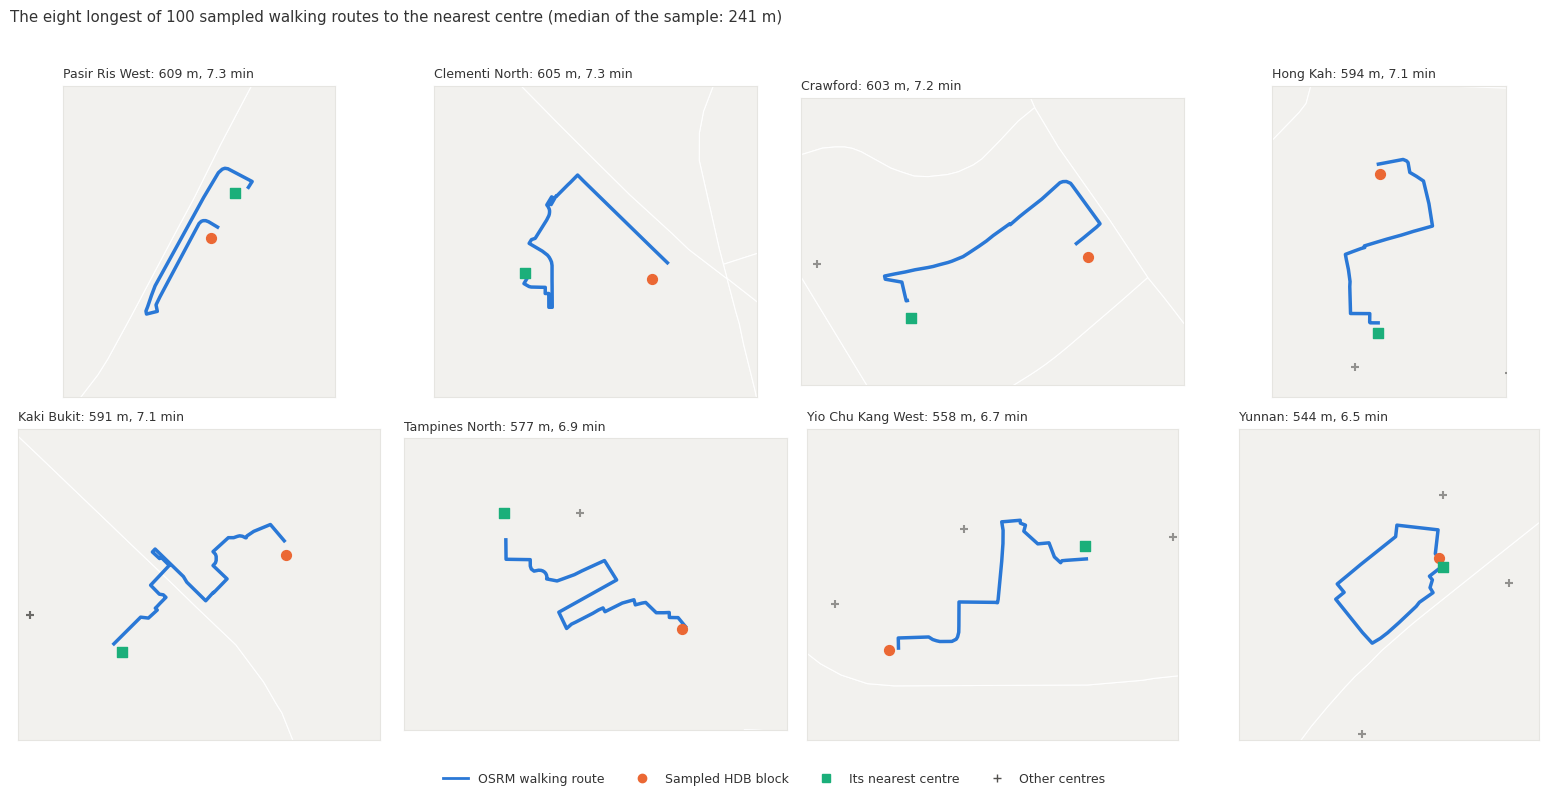

In [5]:
# 1. Static version: at national scale a 240 m route is a dot, so the eight longest of the 100 sampled
#    routes are drawn zoomed, each in its own panel, over the subzone outlines.
routes = gpd.GeoDataFrame(route_records, geometry="geometry", crs="EPSG:4326").to_crs(epsg=3414)
land = gpd.read_file(DATA / "MasterPlanSubZones_2019.geojson").to_crs(epsg=3414)
if len(routes):
    print(f"{len(routes)} routes: median route {routes['route_min'].median():.1f} min / {routes['route_m'].median():.0f} m; "
          f"longest {routes['route_min'].max():.1f} min / {routes['route_m'].max():.0f} m; "
          f"max |route - matrix| = {(routes['route_min'] - routes['matrix_min']).abs().max():.2f} min")
longest = routes.sort_values("route_m", ascending=False).head(8)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, row in zip(axes.ravel(), longest.itertuples()):
    xmin, ymin, xmax, ymax = row.geometry.bounds
    pad = max(150, 0.15 * max(xmax - xmin, ymax - ymin))
    land.plot(ax=ax, facecolor="#f2f1ee", edgecolor="white", linewidth=0.8)
    centres.plot(ax=ax, color=INK2, marker="+", markersize=30, alpha=0.6, zorder=3)
    ax.plot(*row.geometry.xy, color=BLUE, linewidth=2.5, zorder=4)
    blocks.loc[[row.OBJECTID]].plot(ax=ax, color=ORANGE, markersize=50, zorder=5)
    centres.loc[[row.centre_id]].plot(ax=ax, color=AQUA, markersize=50, marker="s", zorder=5)
    ax.set_xlim(xmin - pad, xmax + pad)
    ax.set_ylim(ymin - pad, ymax + pad)
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{blocks.loc[row.OBJECTID, 'SUBZONE_N'].title()}: {row.route_m:,.0f} m, {row.route_min:.1f} min", fontsize=9, loc="left")
fig.legend(handles=[Line2D([], [], color=BLUE, lw=2, label="OSRM walking route"),
                    Line2D([], [], marker="o", ls="none", color=ORANGE, label="Sampled HDB block"),
                    Line2D([], [], marker="s", ls="none", color=AQUA, label="Its nearest centre"),
                    Line2D([], [], marker="+", ls="none", color=INK2, label="Other centres")],
           loc="lower center", ncol=4, frameon=False)
fig.suptitle(f"The eight longest of {len(routes)} sampled walking routes to the nearest centre (median of the sample: "
             f"{routes['route_m'].median():.0f} m)", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0.05, 1, 0.96))
fig.savefig(FIG / "walk_routes_sample.png", dpi=170, bbox_inches="tight")
plt.show()

## 3. Nearest centre per block: cleaning the matrices

Karis's cells 12 and 13. The row minimum of the time matrix is each block's walking time to its
nearest centre; the same for distance. She treated infinite values as missing and dropped
"outliers" beyond 40 minutes or 3,000 m before mapping. With the canonical matrix that filter
removes exactly the three Changi Point blocks (about 50 minutes to the nearest centre); they are
real, not errors, and they are kept in the catchment section and in `hdb_walk_access.csv`.

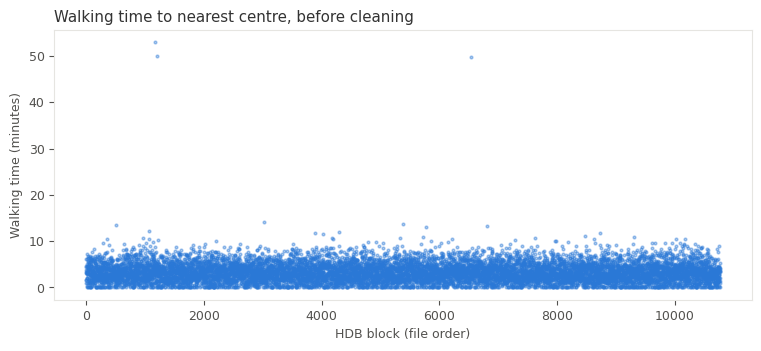

blocks beyond 40 min removed: 3
         BLK_NO       decoded_street     SUBZONE_N  nearest_cc_minutes
OBJECTID                                                              
936727        5  CHANGI VILLAGE ROAD  CHANGI POINT                52.9
936737        4  CHANGI VILLAGE ROAD  CHANGI POINT                50.0
943675        1  CHANGI VILLAGE ROAD  CHANGI POINT                49.9
count    10766.00
mean         3.30
std          1.98
min          0.00
25%          1.86
50%          3.11
75%          4.53
max         14.09


In [6]:
# 1. Treat unreachable routes as missing values (the parquet already stores NaN; kept for safety).
times = walk_time.replace([np.inf, -np.inf], np.nan)

# 2. Minimum walking time across all centres for each HDB block.
hdb_access = blocks.copy()
hdb_access["nearest_cc_minutes"] = times.min(axis=1).reindex(hdb_access.index)

# changed 2026-11-10: axis labels were swapped in the original (x is the block, y the minutes);
# x is now the block's position in the file rather than its OBJECTID.
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.scatter(np.arange(len(hdb_access)), hdb_access["nearest_cc_minutes"], s=4, alpha=0.4, color=BLUE)
ax.set_title("Walking time to nearest centre, before cleaning", loc="left")
ax.set_xlabel("HDB block (file order)")
ax.set_ylabel("Walking time (minutes)")
plt.show()

# 3. Remove outliers > 40 min (Karis's rule).
beyond = hdb_access[hdb_access["nearest_cc_minutes"] > MAX_MINUTES]
print(f"blocks beyond {MAX_MINUTES} min removed: {len(beyond)}")
print(beyond[["BLK_NO", "decoded_street", "SUBZONE_N", "nearest_cc_minutes"]].round(1).to_string())
hdb_access = hdb_access[hdb_access["nearest_cc_minutes"] <= MAX_MINUTES]
print(hdb_access["nearest_cc_minutes"].describe().round(2).to_string())

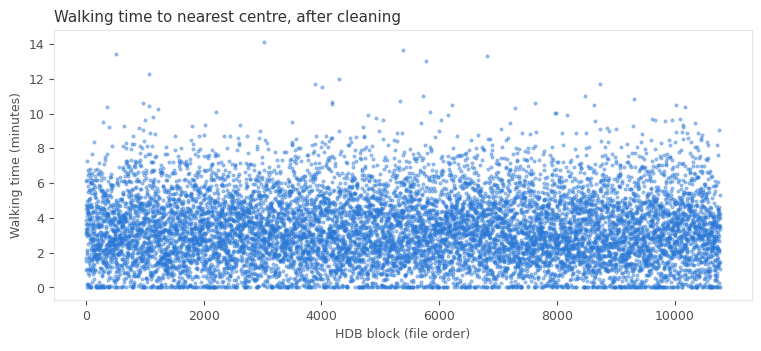

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.scatter(np.arange(len(hdb_access)), hdb_access["nearest_cc_minutes"], s=4, alpha=0.4, color=BLUE)
ax.set_title("Walking time to nearest centre, after cleaning", loc="left")
ax.set_xlabel("HDB block (file order)")
ax.set_ylabel("Walking time (minutes)")
plt.show()

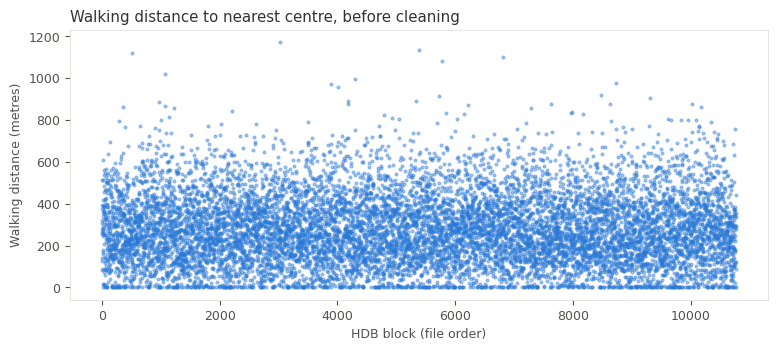

blocks removed by the distance rule: 8
         BLK_NO            decoded_street         SUBZONE_N  nearest_cc_minutes  nearest_cc_distance
OBJECTID                                                                                            
937873      135      BEDOK NORTH STREET 2       BEDOK NORTH                 0.0                 -0.1
940590      817        TAMPINES STREET 81     TAMPINES WEST                 0.0                 -0.1
941992      103  SERANGOON NORTH AVENUE 1  SERANGOON GARDEN                 0.0                 -0.1
941864      159      BEDOK SOUTH AVENUE 3       BEDOK SOUTH                 0.0                 -0.1
945635      124       ANG MO KIO AVENUE 6       KEBUN BAHRU                 0.0                 -0.1
947691       93            PAYA LEBAR WAY        MACPHERSON                 0.0                 -0.1
947692      420     JURONG WEST STREET 42          HONG KAH                 0.0                 -0.1
947066       64     NEW UPPER CHANGI ROAD       BEDO

In [8]:
# 1. Same for distance: minimum walking metres across all centres.
distances = walk_dist.replace([np.inf, -np.inf], np.nan)
hdb_access["nearest_cc_distance"] = distances.min(axis=1).reindex(hdb_access.index)

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.scatter(np.arange(len(hdb_access)), hdb_access["nearest_cc_distance"], s=4, alpha=0.4, color=BLUE)
ax.set_title("Walking distance to nearest centre, before cleaning", loc="left")
ax.set_xlabel("HDB block (file order)")
ax.set_ylabel("Walking distance (metres)")
plt.show()

# 2. Remove outliers > 3,000 m or negative (Karis's rule). Nothing is above 3,000 m once the three
#    Changi Point blocks are gone; the "negative" half of the rule catches blocks whose nearest centre is
#    in the same building, which OSRM reports as -0.1 m (snapping/rounding artefact, time 0.0 min).
dropped = hdb_access[~((hdb_access["nearest_cc_distance"] <= MAX_METRES) & (hdb_access["nearest_cc_distance"] >= 0))]
print(f"blocks removed by the distance rule: {len(dropped)}")
print(dropped[["BLK_NO", "decoded_street", "SUBZONE_N", "nearest_cc_minutes", "nearest_cc_distance"]].to_string())
hdb_access = hdb_access[(hdb_access["nearest_cc_distance"] <= MAX_METRES) & (hdb_access["nearest_cc_distance"] >= 0)]
print(f"{len(hdb_access):,} blocks remain")
print(hdb_access["nearest_cc_distance"].describe().round(1).to_string())

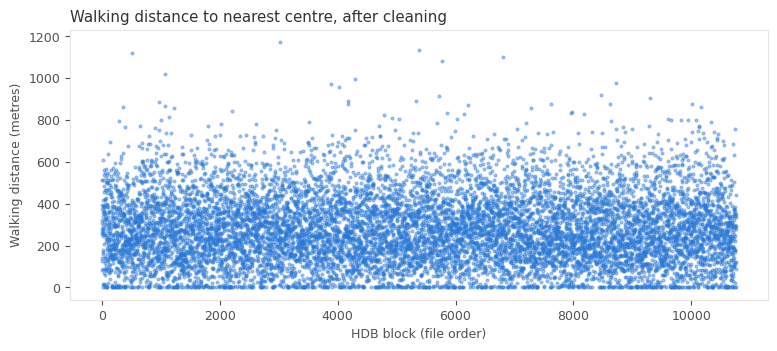

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.scatter(np.arange(len(hdb_access)), hdb_access["nearest_cc_distance"], s=4, alpha=0.4, color=BLUE)
ax.set_title("Walking distance to nearest centre, after cleaning", loc="left")
ax.set_xlabel("HDB block (file order)")
ax.set_ylabel("Walking distance (metres)")
plt.show()

### What the first statistics say

The median block is about three minutes (roughly 280 m) from a centre and three quarters of blocks
are within five minutes / 400 m. Walking access to *a* centre is close to universal in HDB
estates, which is why the later stages do not test a binary "has access" but supply per child and
the walk-time distribution (Karis's note, confirmed on the canonical data).

## 4. Maps of walking time and distance to the nearest centre

Every block coloured by its nearest-centre walking time (then distance) on one Blues ramp, darker
= farther; centres as grey crosses. (Karis used a red–green ramp; replaced by the repo palette.)

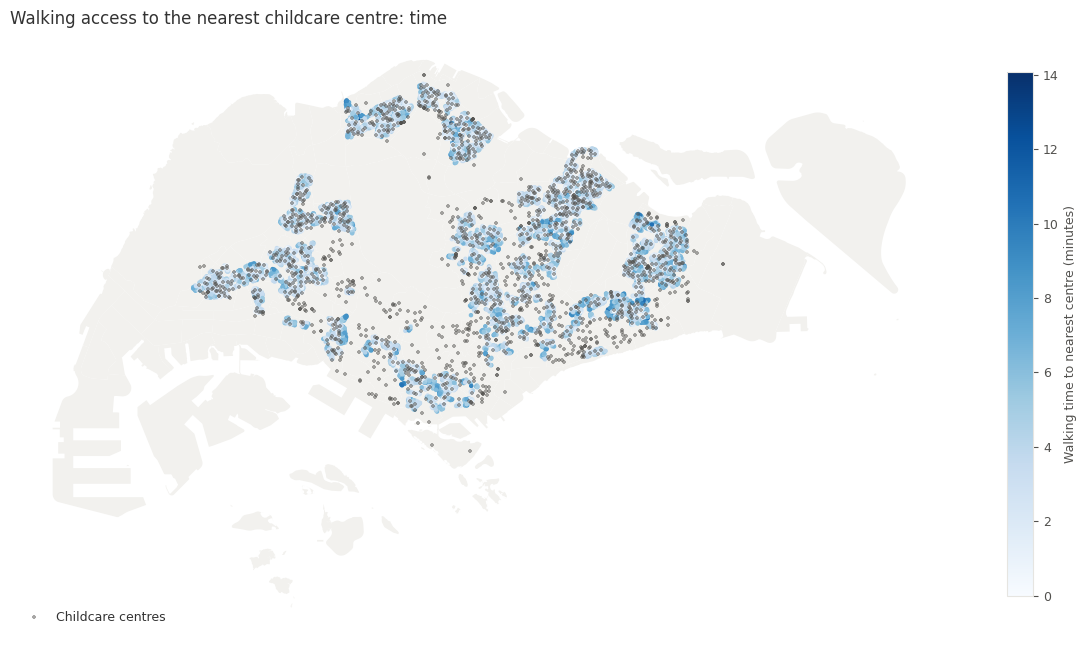

In [10]:
fig, ax = plt.subplots(figsize=(12, 9))
land.plot(ax=ax, facecolor="#f2f1ee", edgecolor="none")
hdb_access.plot(column="nearest_cc_minutes", cmap="Blues", markersize=5, legend=True,
                legend_kwds={"label": "Walking time to nearest centre (minutes)", "shrink": 0.6},
                missing_kwds={"color": "lightgrey", "label": "No reachable centre"}, ax=ax)
centres.plot(ax=ax, color=INK2, marker="+", markersize=8, alpha=0.5, label="Childcare centres")
ax.set_title("Walking access to the nearest childcare centre: time", loc="left", fontsize=12)
ax.set_axis_off()
ax.legend(loc="lower left", frameon=False)
fig.tight_layout()
fig.savefig(FIG / "walk_nearest_time_map.png", dpi=170, bbox_inches="tight")
plt.show()

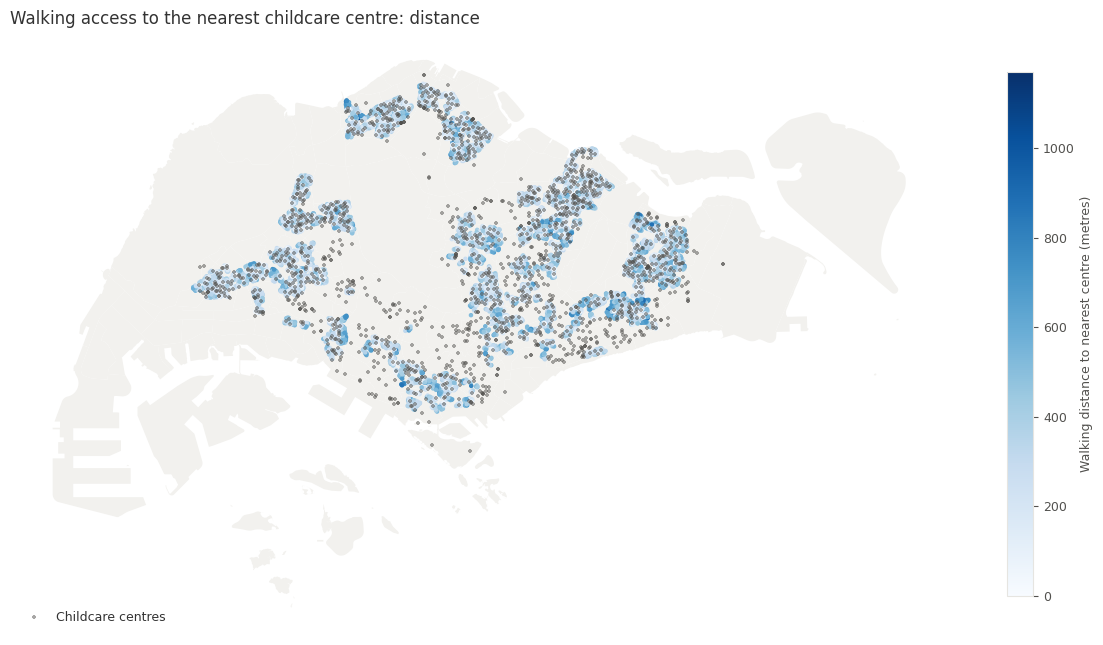

In [11]:
fig, ax = plt.subplots(figsize=(12, 9))
land.plot(ax=ax, facecolor="#f2f1ee", edgecolor="none")
hdb_access.plot(column="nearest_cc_distance", cmap="Blues", markersize=5, legend=True,
                legend_kwds={"label": "Walking distance to nearest centre (metres)", "shrink": 0.6},
                missing_kwds={"color": "lightgrey", "label": "No reachable centre"}, ax=ax)
centres.plot(ax=ax, color=INK2, marker="+", markersize=8, alpha=0.5, label="Childcare centres")
ax.set_title("Walking access to the nearest childcare centre: distance", loc="left", fontsize=12)
ax.set_axis_off()
ax.legend(loc="lower left", frameon=False)
fig.tight_layout()
fig.savefig(FIG / "walk_nearest_distance_map.png", dpi=170, bbox_inches="tight")
plt.show()

*Dropped here:* Karis's cells 17–18 (geoplot KDE of HDB and centre points, equal weights) are
superseded by the child-weighted KDE in `2_02_child_density_kde.ipynb`, and `geoplot` is not
installed; cells 22–23 (Ripley's K) are `2_03_ripleys_k.ipynb`.

## 5. 5-, 10- and 15-minute walking catchments

Karis's cells 20 and 21, on **all** blocks (before the outlier filters). A block is "within" a
threshold if at least one centre is reachable in that time; it is "confirmed beyond" only when all
its destination times are known and none qualifies; otherwise "unknown". These are point-based
network catchments (each block counts equally, no interpolation, no buffers), not population-
weighted coverage.

One fix: the two Changi Airport centres are NaN for every block, which under the original rule made
*every* block "unknown" (her run reported 10,769 incomplete rows). Those two all-NaN columns are
dropped before the completeness check, so the only blocks confirmed beyond 15 minutes are the three
at Changi Point.

In [12]:
# changed 2026-11-10: drop destinations no block can reach (the two airport centres), otherwise the
# completeness rule below classifies every block as "unknown" instead of "beyond threshold".
catchment_times = walk_time.drop(columns=unreachable_centres)
print(f"destinations used: {catchment_times.shape[1]:,} of {walk_time.shape[1]:,} centres")

# 1. Missing, infinite or negative values are unknown.
catchment_times = catchment_times.where(np.isfinite(catchment_times) & catchment_times.ge(0))
hdb_catchments = blocks.copy()
hdb_catchments["nearest_cc_minutes"] = catchment_times.min(axis=1)
hdb_catchments["complete_times"] = catchment_times.notna().all(axis=1)

# 2. Coverage per threshold: covered / confirmed beyond / unknown, plus reachable-centre counts.
coverage_rows = []
for minutes in THRESHOLDS:
    counts = catchment_times.le(minutes).sum(axis=1)
    covered = counts.gt(0)
    beyond = ~covered & hdb_catchments["complete_times"]
    unknown = ~covered & ~hdb_catchments["complete_times"]
    hdb_catchments[f"ccs_within_{minutes}min"] = counts
    hdb_catchments[f"access_{minutes}min"] = np.select([covered, beyond], ["Within threshold", "Beyond threshold"], default="Unknown")
    coverage_rows.append({"Threshold (minutes)": minutes, "HDBs covered": int(covered.sum()),
                          "Coverage (% of all HDBs)": round(100 * covered.mean(), 2),
                          "HDBs confirmed beyond": int(beyond.sum()), "HDBs unknown": int(unknown.sum()),
                          "Median known reachable CCs per HDB": float(counts.median())})
catchment_summary = pd.DataFrame(coverage_rows).set_index("Threshold (minutes)")
print(catchment_summary.to_string())
print(f"\nDenominator: {len(hdb_catchments):,} HDB points. "
      f"{(~hdb_catchments['complete_times']).sum():,} HDBs have incomplete route times.")
print("blocks confirmed beyond 15 minutes:")
print(hdb_catchments.loc[hdb_catchments["access_15min"] == "Beyond threshold",
                         ["BLK_NO", "decoded_street", "SUBZONE_N", "nearest_cc_minutes"]].round(1).to_string())

# 3. Cross-check against the committed summary (counts within 10 / 15 min per block).
for minutes in (10, 15):
    diff = (hdb_catchments[f"ccs_within_{minutes}min"] - walk_access[f"centres_n_within_{minutes}min"]).abs().max()
    print(f"max |count within {minutes} min - hdb_walk_access| = {diff}")

destinations used: 1,794 of 1,796 centres


                     HDBs covered  Coverage (% of all HDBs)  HDBs confirmed beyond  HDBs unknown  Median known reachable CCs per HDB
Threshold (minutes)                                                                                                                 
5                            8753                     81.28                   2016             0                                 1.0
10                          10736                     99.69                     33             0                                 7.0
15                          10766                     99.97                      3             0                                17.0

Denominator: 10,769 HDB points. 0 HDBs have incomplete route times.
blocks confirmed beyond 15 minutes:
         BLK_NO       decoded_street     SUBZONE_N  nearest_cc_minutes
OBJECTID                                                              
936727        5  CHANGI VILLAGE ROAD  CHANGI POINT                52.9
936737        4  

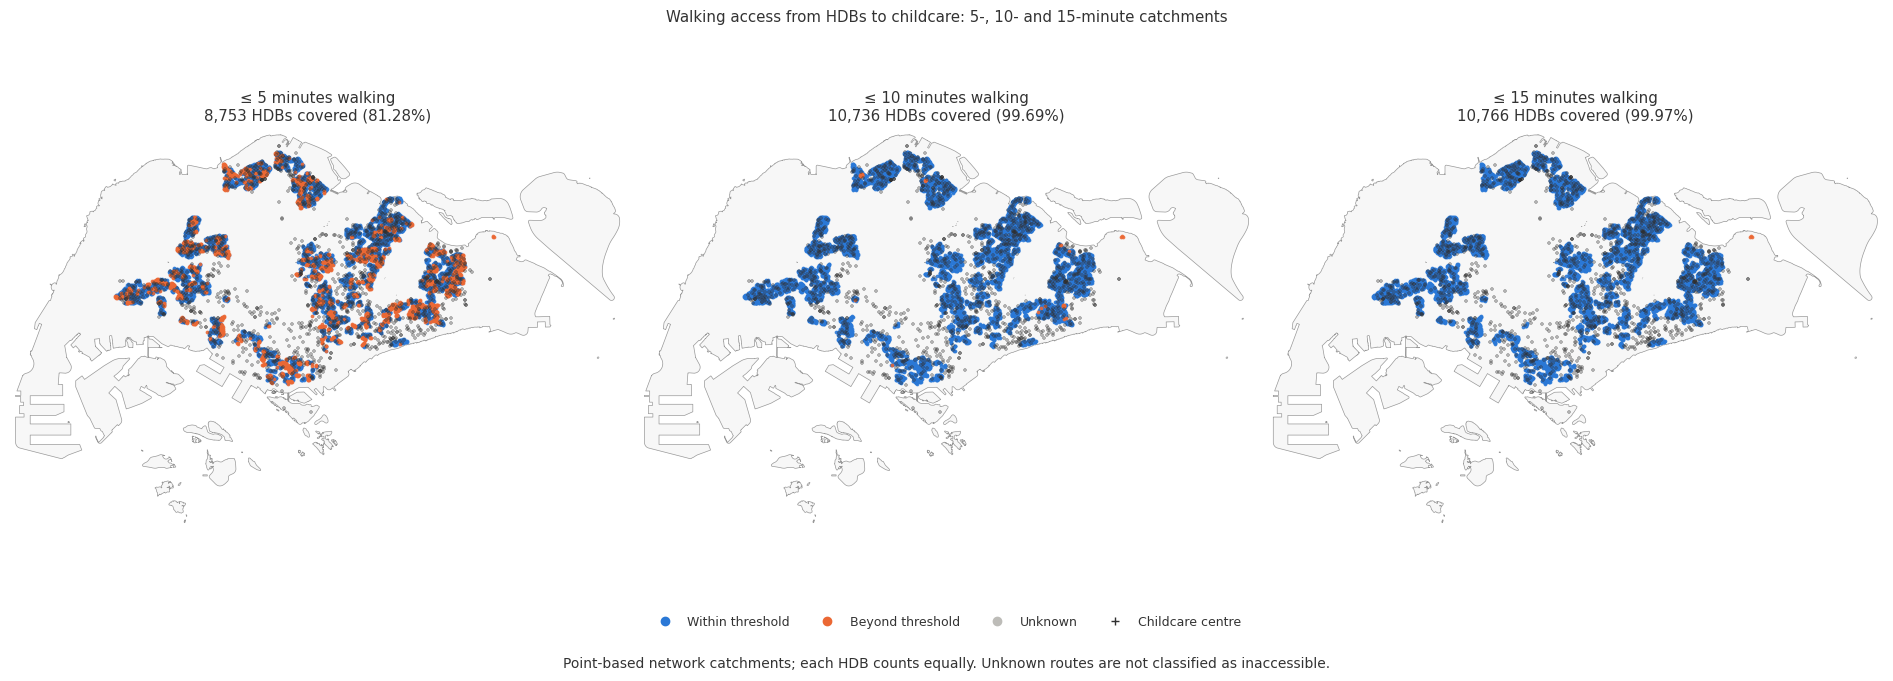

In [13]:
# 1. Three panels, one per threshold, in the metric CRS; repo palette for the three classes.
catchment_boundary = land.dissolve()
xmin, ymin, xmax, ymax = catchment_boundary.total_bounds
padding = 500  # metres
colours = {"Within threshold": BLUE, "Beyond threshold": ORANGE, "Unknown": "#bdbcb8"}
fig, axes = plt.subplots(1, 3, figsize=(19, 7))
for ax, minutes in zip(axes, THRESHOLDS):
    catchment_boundary.plot(ax=ax, facecolor="#f7f7f7", edgecolor="#999999", linewidth=0.5)
    for status in ["Within threshold", "Beyond threshold", "Unknown"]:
        subset = hdb_catchments.loc[hdb_catchments[f"access_{minutes}min"].eq(status)]
        if not subset.empty:
            subset.plot(ax=ax, color=colours[status], markersize=3, alpha=0.8)
    centres.plot(ax=ax, color="#303030", marker="+", markersize=6, alpha=0.35)
    row = catchment_summary.loc[minutes]
    ax.set_title(f"≤ {minutes} minutes walking\n{int(row['HDBs covered']):,} HDBs covered ({row['Coverage (% of all HDBs)']:.2f}%)")
    ax.set_xlim(xmin - padding, xmax + padding)
    ax.set_ylim(ymin - padding, ymax + padding)
    ax.set_aspect("equal")
    ax.set_axis_off()
handles = [Line2D([], [], marker="o", linestyle="none", color=c, label=s) for s, c in colours.items()]
handles.append(Line2D([], [], marker="+", linestyle="none", color="#303030", label="Childcare centre"))
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 0.08))
fig.suptitle("Walking access from HDBs to childcare: 5-, 10- and 15-minute catchments")
fig.text(0.5, 0.04, "Point-based network catchments; each HDB counts equally. Unknown routes are not classified as inaccessible.",
         ha="center", fontsize=10)
plt.tight_layout(rect=(0, 0.15, 1, 0.94))
fig.savefig(FIG / "walk_catchments_5_10_15.png", dpi=170, bbox_inches="tight")
plt.show()

In [14]:
for name in ["walk_routes_sample.html", "walk_routes_sample.png", "walk_nearest_time_map.png",
             "walk_nearest_distance_map.png", "walk_catchments_5_10_15.png"]:
    print(f"wrote figures/{name}  ({(FIG / name).stat().st_size / 1e6:.1f} MB)")
print(f"\n{len(hdb_access):,} blocks on the nearest-centre maps; {len(hdb_catchments):,} in the catchment panels")

wrote figures/walk_routes_sample.html  (2.4 MB)
wrote figures/walk_routes_sample.png  (0.2 MB)
wrote figures/walk_nearest_time_map.png  (0.4 MB)
wrote figures/walk_nearest_distance_map.png  (0.4 MB)
wrote figures/walk_catchments_5_10_15.png  (0.5 MB)

10,758 blocks on the nearest-centre maps; 10,769 in the catchment panels
